# SFT: data prep

In [4]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import sys, json, urllib.request
from pathlib import Path
import numpy as np
from tokenizers import Tokenizer

ROOT = Path("..").resolve()                 # use Path(".").resolve() if the notebook is in the repo root
sys.path.insert(0, str(ROOT / "scripts"))
from prep_sft import parse_turns, pack_chunks, split_chunks, write_bin

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
RAW = ROOT / "data_sft" / "raw" / "input.txt"
RUN = ROOT / "runs" / "pretrain_v2"
OUT = ROOT / "data_sft_test"                # scratch folder, safe to delete
MAX_TOKENS = 224

# --- raw data -----------------------------------------------------------
RAW.parent.mkdir(parents=True, exist_ok=True)
if not RAW.exists():
    urllib.request.urlretrieve(URL, RAW)
text = RAW.read_text(encoding="utf-8")
print(f"raw: {len(text):,} chars")
print(text[:300], "\n" + "-" * 60)

# --- pretrained tokenizer (never trained here) ------------------------------
tok = Tokenizer.from_file(str(RUN / "tokenizer.json"))
eot_id = tok.token_to_id("<|endoftext|>")
meta = json.load(open(RUN / "meta.json"))
assert tok.get_vocab_size() == meta["vocab_size"] == 4096
assert eot_id == meta["eot_id"] == 0

# --- 1) turns ------------------------------------------------------------
turns = parse_turns(text)
bad = [t for t in turns if not t.splitlines()[0].rstrip().endswith(":")]
print(f"{len(turns)} turns; {len(bad)} don't start with a speaker line")
for t in bad[:3]:
    print("   e.g.", repr(t[:80]))

# --- 2) packing ----------------------------------------------------------
chunks = pack_chunks(turns, tok, MAX_TOKENS)
assert "\n\n".join(chunks) == "\n\n".join(turns), "turns lost or duplicated while packing"
lens = [len(tok.encode(c).ids) for c in chunks]
print(f"{len(chunks)} chunks | tokens/chunk: mean {np.mean(lens):.0f}, max {max(lens)}, over budget: {sum(l > MAX_TOKENS for l in lens)}")
print("chunks starting with a speaker line:", sum(c.splitlines()[0].rstrip().endswith(":") for c in chunks), "/", len(chunks))

# --- 3) split ------------------------------------------------------------
train_chunks, val_chunks = split_chunks(chunks, val_every=10, mode="interleaved")
index_of = {c: i for i, c in enumerate(chunks)}
assert not (set(train_chunks) & set(val_chunks)), "a chunk is in both splits"
assert len(train_chunks) + len(val_chunks) == len(chunks)
pos = [index_of[v] for v in val_chunks]
print(f"train {len(train_chunks)} / val {len(val_chunks)} chunks | val positions: first {pos[0]}, middle {pos[len(pos)//2]}, last {pos[-1]} (of {len(chunks)})")

# --- 4) write and read back -----------------------------------------------
for name, chs in (("train", train_chunks), ("val", val_chunks)):
    info = write_bin(chs, tok, eot_id, OUT / f"{name}.bin")
    arr = np.fromfile(OUT / f"{name}.bin", dtype=np.uint16)
    assert arr.size == info["tokens"]
    assert arr[0] == eot_id
    assert int((arr == eot_id).sum()) == len(chs), "eot count != chunk count"
    assert int(arr.max()) < tok.get_vocab_size()
    ends = np.flatnonzero(arr[1:] == eot_id)
    end = int(ends[0]) + 1 if len(ends) else arr.size
    assert tok.decode(arr[1:end].tolist()) == chs[0], "round trip failed"
    print(f"{name}: {info['chunks']} chunks, {info['tokens']:,} tokens, "
          f"{info['tokens']/info['chunks']:.1f} tokens/chunk, {info['chars']/info['tokens']:.2f} chars/token")
    if info["tokens"] < 10_000:
        print(f"   warning: {name} has under 10k tokens, so the loss estimate will be noisy")

print("\n" + "-" * 60)
print(tok.decode(np.fromfile(OUT / "train.bin", dtype=np.uint16)[:300].tolist(), skip_special_tokens=False))

raw: 1,115,394 chars
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us 
------------------------------------------------------------
7222 turns; 0 don't start with a speaker line
2261 chunks | tokens/chunk: mean 197, max 1099, over budget: 246
chunks starting with a speaker line: 2261 / 2261
train 2041 / val 220 chunks | val positions: first 90, middle 1190, last 2199 (of 2261)
train: 2041 chunks, 403,451 tokens, 197.7 tokens/chunk, 2.48 chars/token
val: 220 chunks, 44,011 tokens, 200.1 tokens/chunk, 2.47 chars/token

------------------------------------------------------------
<|endoftext|>First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

Al

In [ ]:
from gpt.config import load_config
cfg = load_config("configs/tiny.yaml", data_dir="data_sft")
print(cfg.vocab_size)        # 4096, read from data_sft/meta.json

/Users/marzioformica/Desktop/swGPT
4096


## Compare FT

['2026-10-25_1209_tiny', '2026-10-25_1213_tiny', '2026-10-25_1342_tiny', 'pretrain_v2', 'resume_a', 'resume_b', 'sft_lr1e-4', 'sft_lr3e-4', 'sft_scratch', 'sft_smoke', 'wandb_test']


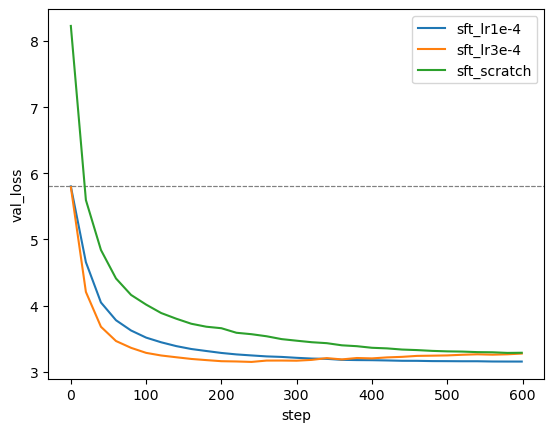

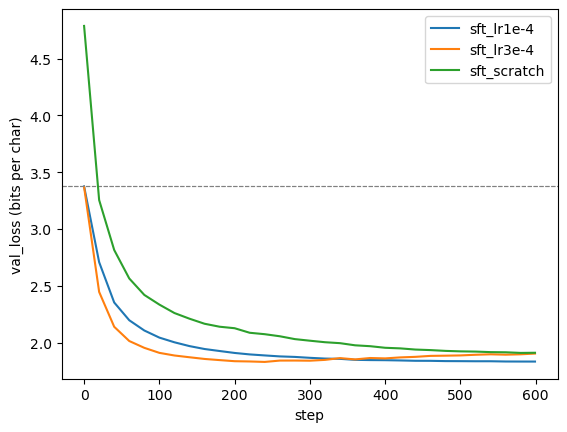

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import math

RUNS = Path("runs")          # use Path("runs") if the notebook is in the repo root
print(sorted(p.name for p in RUNS.iterdir()))


def load_run(name):
    df = pd.read_json(RUNS / name / "metrics.jsonl", lines=True)
    # a resumed run repeats some steps; the baseline row shares step 0 with the first eval.
    # groupby().last() keeps the last non-null value of each column per step.
    return df.groupby("step").last().reset_index()


def compare(names, col="val_loss", chars_per_token=None):
    # chars_per_token (e.g. 2.48) converts nats/token to bits per char, so runs are comparable across tokenizers
    for n in names:
        df = load_run(n)
        y = df[col] if chars_per_token is None else df[col] / (math.log(2) * chars_per_token)
        plt.plot(df.step, y, label=n)
        if "baseline_val_loss" in df and df.baseline_val_loss.notna().any():
            b = df.baseline_val_loss.dropna().iloc[0]
            b = b if chars_per_token is None else b / (math.log(2) * chars_per_token)
            plt.axhline(b, linestyle="--", color="gray", linewidth=0.8)    # pretrained model before finetuning
    plt.xlabel("step")
    plt.ylabel(col if chars_per_token is None else f"{col} (bits per char)")
    plt.legend()
    plt.show()


compare(["sft_lr1e-4", "sft_lr3e-4", "sft_scratch"])
compare(["sft_lr1e-4", "sft_lr3e-4", "sft_scratch"], chars_per_token=2.48)

## Generation

In [16]:
# CELL 1: setup and samples
%load_ext autoreload
%autoreload 2
import re, json, torch, numpy as np
from collections import Counter
from tokenizers import Tokenizer
from gpt.generate import load_model, generate

PRE  = "runs/pretrain_v2"
SFT  = "runs/sft_lr1e-4"        # folder of the finetuning run
DATA = "data_sft"

tok = Tokenizer.from_file(f"{PRE}/tokenizer.json")          # the finetuning data uses a copy of this same tokenizer
eot_id = tok.token_to_id("<|endoftext|>")

paths = {"pretrained": f"{PRE}/best.pt", "finetuned": f"{SFT}/best.pt"}   # best.pt, not last.pt (last.pt may hold NaN weights)
models = {}
for name, path in paths.items():
    m, c = load_model(path)
    assert all(torch.isfinite(p).all() for p in m.parameters()), f"{name}: non-finite weights"
    models[name] = (m, c)

# speaker names that actually occur in the data, for choosing prompts
raw = open(f"{DATA}/raw/input.txt", encoding="utf-8").read()
speakers = Counter(re.findall(r"^([A-Za-z' ]+):$", raw, flags=re.M))
print("most common speakers:", [s for s, _ in speakers.most_common(12)], "\n")


def sample(name, prompt, seed=0, max_new_tokens=150, temperature=0.8, k=50):
    model, cfg = models[name]
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([[eot_id] + tok.encode(prompt).ids])           # every training document starts after an eot token
    out = generate(model, cfg.context_len, idx, max_new_tokens, temperature, k, g, eot_id)
    return out[0, 1:].tolist()


prompts = ["", "First Citizen:\n", "ROMEO:\n", "Once upon a time"]       # unconditional, speaker-tagged, story-style
for prompt in prompts:
    for name in models:
        ids = sample(name, prompt, seed=0)
        print(f"===== {name} | prompt {prompt!r} =====")
        print(tok.decode(ids), "\n")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


TypeError: Config.__init__() got an unexpected keyword argument 'device'

In [ ]:
# CELL 2: three numbers per model, from unconditional samples
N_GRAM, N_SAMPLES = 8, 10                          # raise N_SAMPLES for steadier numbers (CPU generation is slow without a cache)
train = np.fromfile(f"{DATA}/train.bin", dtype=np.uint16).tolist()
train_grams = {tuple(train[i:i + N_GRAM]) for i in range(len(train) - N_GRAM + 1)}


def overlap(ids):                                  # fraction of generated 8-grams that occur verbatim in the training data
    grams = [tuple(ids[i:i + N_GRAM]) for i in range(len(ids) - N_GRAM + 1)]
    return sum(g in train_grams for g in grams) / max(1, len(grams))


for name in models:
    stats = []
    for seed in range(N_SAMPLES):
        ids = sample(name, "", seed=seed, max_new_tokens=200)
        text = tok.decode(ids)
        n_speaker_lines = len(re.findall(r"^[A-Za-z' ]+:$", text, flags=re.M))
        stats.append((len(ids), n_speaker_lines, overlap(ids)))
    L, S, O = np.mean(stats, axis=0)
    print(f"{name:11s} tokens {L:6.1f} | speaker tags per sample {S:4.1f} | 8-gram overlap with train {O:5.1%}")